In [5]:
import os
import json

import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
SEQ_CSV_PATH = "../seq_files.csv"
df = pd.read_csv(SEQ_CSV_PATH)
df.head()

,seq_name,seq_path,avi_path,frame_h,frame_w,camera_type,altitude
0,Noise_1_enter_exit_NoSw_28_16_15_11_2015.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling...,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling...,720.0,1280.0,NaN,253
1,PG1_dev_H660_Walk_Q_BlackCarpet_NY_Q_150928576...,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev2_h...,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling...,960.0,1280.0,SunPlus_PG_Camera,660
2,PG1_DL_H300_Walking_NY_St1707_1500538480.avi.seq,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling...,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling...,960.0,1280.0,SunPlus_PG1_Camera1,300
3,PG1_dev_H270_VLC_3mHall_Door_05Wall_1509468343...,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_VL...,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling...,960.0,1280.0,SunPlus_PG_Camera,270
4,PG1_H300_MR_SquareSeat_NY_15stnd_1509274685.av...,/mnt/pg-fs01/Current/Benchmarks/PG1_AlgoDev_DL...,/mnt/pg-fs01/Current/DB/Home_Appliance/Ceiling...,960.0,1280.0,SunPlus_PG_Camera,300


In [25]:
with open("splitting.json", "rt") as f:
    splitting = json.load(f)
    
splitting["algo_ci_test"] = df[
    (~df["seq_name"].isin(splitting["train"])) & \
    (~df["seq_name"].isin(splitting["val"])) & \
    (~df["seq_name"].isin(splitting["hold-out"]))
]["seq_name"].values.tolist()

In [26]:
def represent(seq_names, title="train", n=5, seed=42):
    tmp_names = seq_names[:]
    np.random.seed(seed)
    np.random.shuffle(tmp_names)
    tmp_names = tmp_names[:n]
    
    plt.figure(figsize=(15, 3))
    for i, seq_name in enumerate(tmp_names):
        avi_pth = df[df["seq_name"] == seq_name].reset_index().iloc[0]["avi_path"]
        # print(avi_pth)
        
        N = 50
        cap = cv2.VideoCapture(avi_pth)

        frame = None
        count = -1
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            count += 1
            if count >= N:
                break
        cap.release()
        
        plt.subplot(1, n, i + 1)
        plt.imshow(frame)
    
    plt.tight_layout()
    plt.suptitle(title)

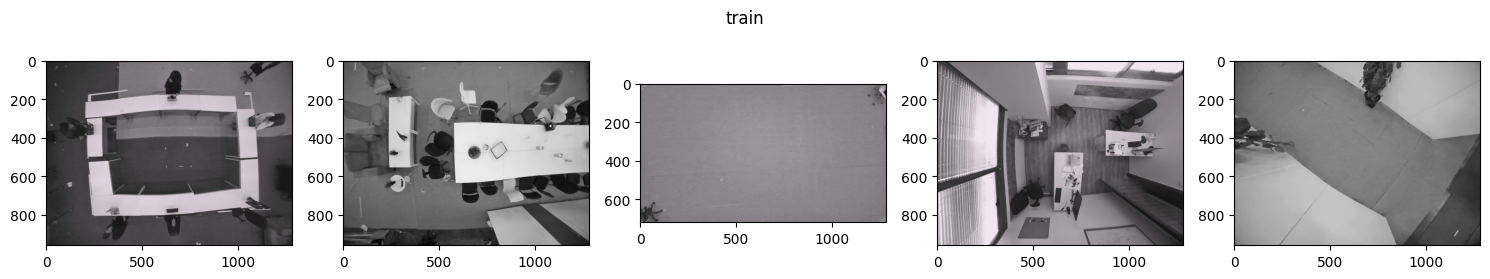

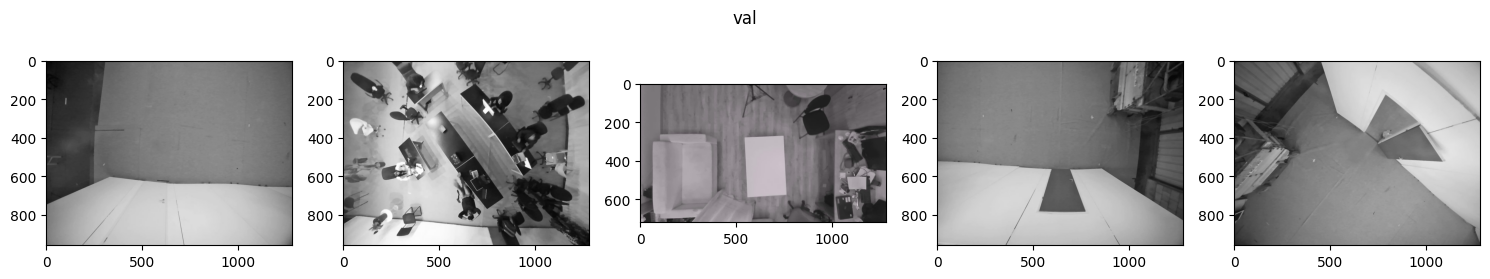

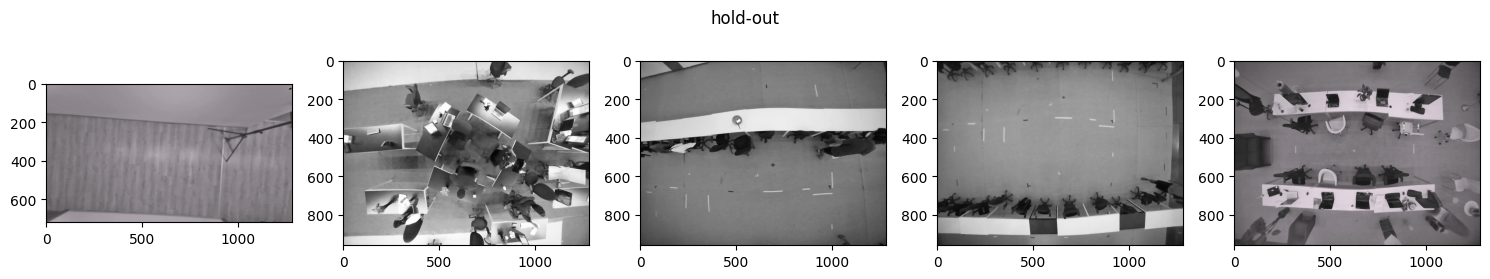

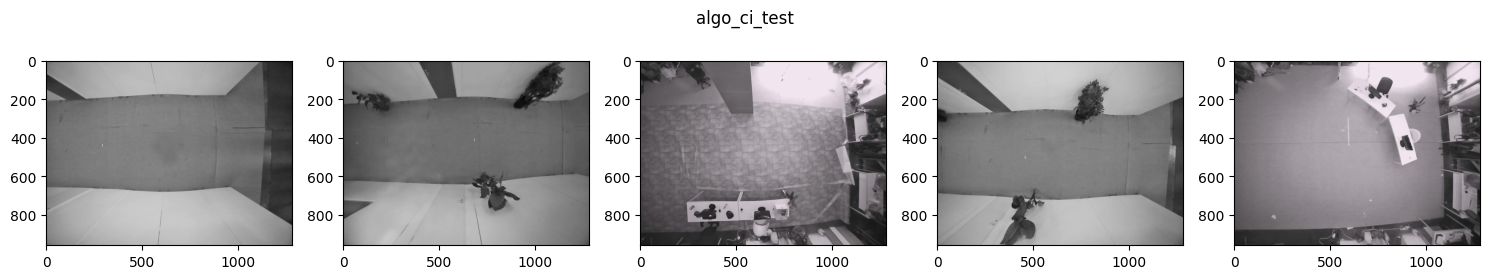

In [28]:
represent(splitting["train"])
represent(splitting["val"], "val")
represent(splitting["hold-out"], "hold-out")
represent(splitting["algo_ci_test"], "algo_ci_test")

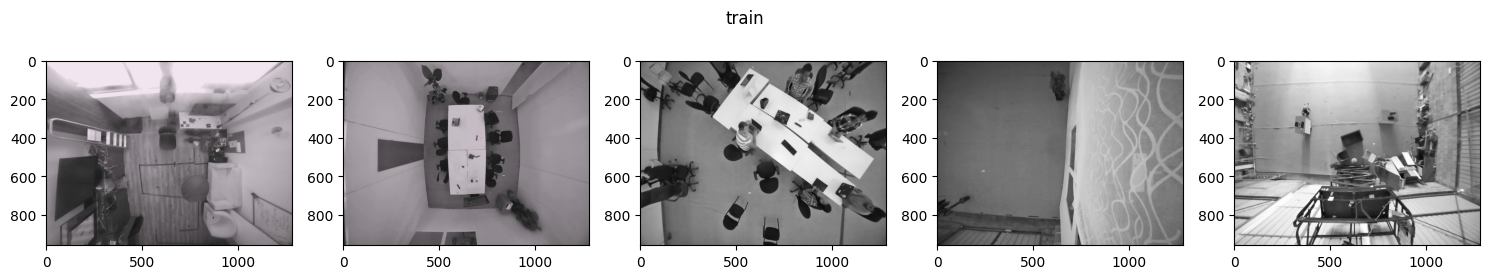

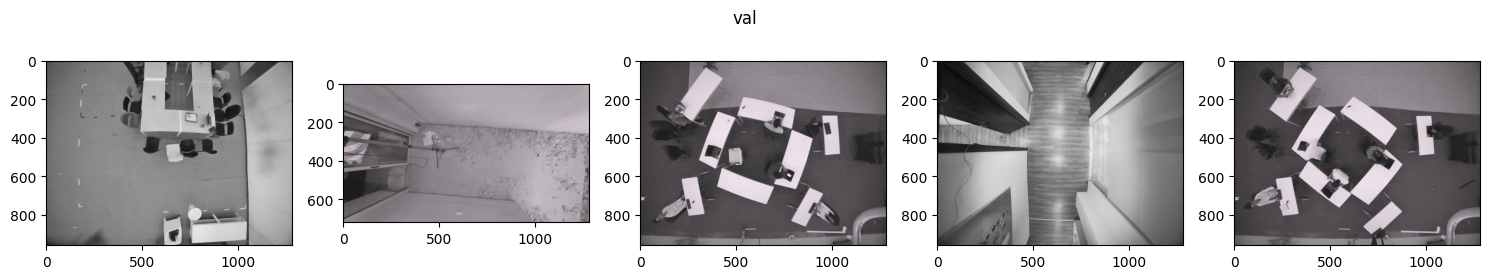

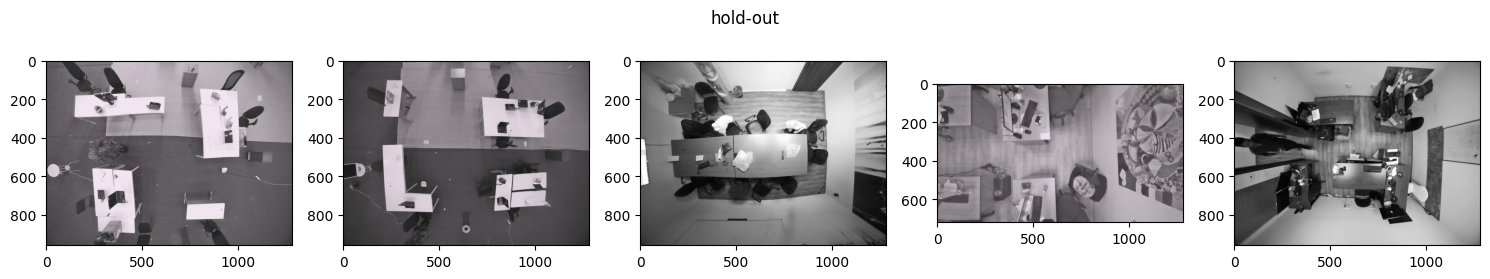

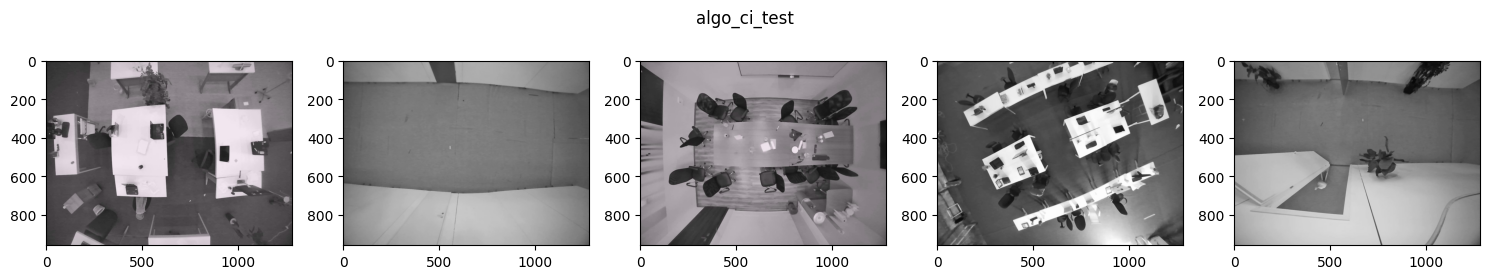

In [29]:
seed = 11
represent(splitting["train"], seed=seed)
represent(splitting["val"], "val", seed=seed)
represent(splitting["hold-out"], "hold-out", seed=seed)
represent(splitting["algo_ci_test"], "algo_ci_test", seed=seed)